# 01 Dataset exploration (real metadata)
Runs on the public BIDS metadata of ds007526 and ds002778 fetched by `scripts/fetch_metadata.py`. No EEG signals are used here. Run from the repository root.

In [1]:
import os; os.chdir('..') if os.path.basename(os.getcwd())=='notebooks' else None
import matplotlib.pyplot as plt
import pandas as pd

from ndpred.data import bids

A = bids.load_ds007526('data/raw/ds007526'); B = bids.load_ds002778('data/raw/ds002778')
print(A.groupby('group').size().to_dict(), B.groupby('group').size().to_dict())

{'HC': 28, 'PD': 116} {'HC': 16, 'PD': 15}


## ds007526: group composition and clinical variable availability

In [2]:
print(A.notna().sum().to_string())
print(A.groupby('group')[['age','moca','updrs_iii','updrs_total']].agg(['count','mean','std']).round(2).T)

participant_id      144
cohort              144
group               144
age                 144
sex                 144
moca                140
updrs_iii           139
updrs_total         139
disease_duration    116
ledd                115
label               144
group                 HC      PD
age         count  28.00  116.00
            mean   60.82   66.13
            std     7.47    9.40
moca        count  27.00  113.00
            mean   27.44   25.16
            std     1.97    3.13
updrs_iii   count  26.00  113.00
            mean    1.38   24.75
            std     1.75   12.48
updrs_total count  26.00  113.00
            mean    3.27   40.26
            std     3.34   20.55


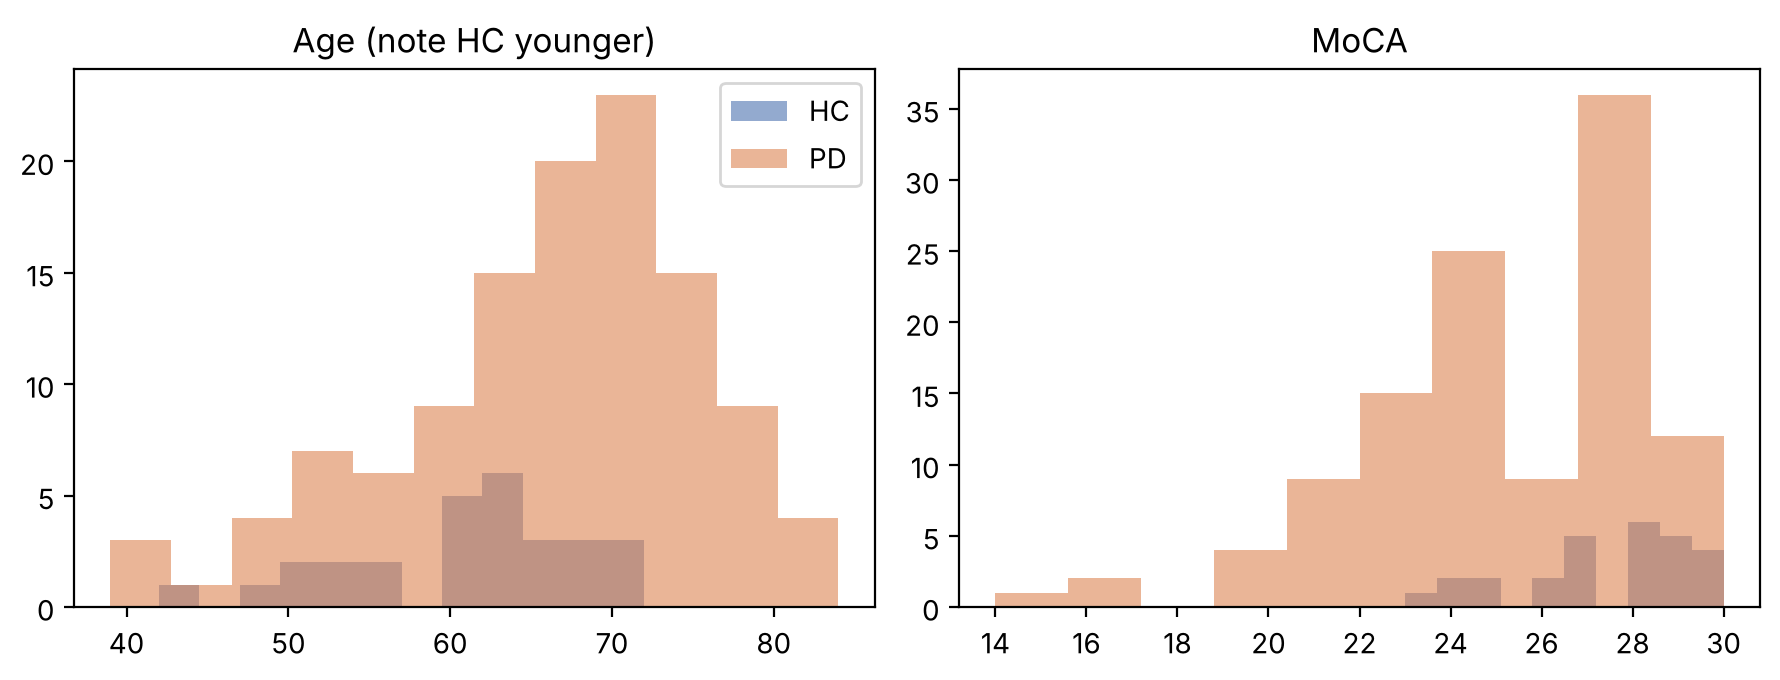

In [3]:
fig, ax = plt.subplots(1,2, figsize=(9,3.5))
for g, c in (('HC','#4C72B0'),('PD','#DD8452')):
    ax[0].hist(A[A.group==g].age, bins=12, alpha=.6, label=g, color=c)
    ax[1].hist(A[A.group==g].moca.dropna(), bins=10, alpha=.6, label=g, color=c)
ax[0].set_title('Age (note HC younger)'); ax[1].set_title('MoCA'); ax[0].legend(); plt.tight_layout()

## ds002778: groups, scores, Hoehn & Yahr (PD, per session)

In [4]:
print(B.groupby('group')[['age','mmse','naart']].agg(['count','mean','std']).round(2).T)
S = bids.load_ds002778_sessions('data/raw/ds002778')
print(pd.crosstab(S.session, S.hoehn_yahr))

group           HC     PD
age   count  16.00  15.00
      mean   63.50  63.27
      std     9.67   8.20
mmse  count  16.00  15.00
      mean   29.19  28.93
      std     1.11   1.03
naart count  16.00  15.00
      mean   49.12  46.13
      std     7.14   6.47
hoehn_yahr  2.0  3.0
session             
off           8    7
on            7    8


**Observation.** In ds007526 healthy controls are younger and far fewer than PD participants (28 vs 116); in ds002778 H&Y takes only two values in 15 patients. Both facts constrain what can be modelled.